# Kepler meets Bayes - The estimation of the Earth's orbit eccentricity using NumPyro

This notebook calculates the earth's orbit eccentricity using data not unlike Kepler's and estimates the uncertainty of the estimation using Bayesian analysis.

The Earth's orbit is almost circular: it is an ellipse with a small eccentricity of about 0.0167 and Kepler's estimation was of about 0.017. This is, however, a point estimation; noise in Kepler's data should have become uncertainty in the estimation. This  notebook in an attempt to qualify this point estimate with an estimate of its variability.

Having been unable to get a precise dataset with Kepler's original data, I have resorted to a dataset provided by Luca Canali, to whom I am greatly thankful. In particular, I am using his [`ephemeris_mars_sun.csv`](https://github.com/LucaCanali/Miscellaneous/blob/master/Data_Analyses/Kepler/Data/ephemeris_mars_sun.csv) dataset (which does not come from Tycho Brahe but from the NASA).

The particular dataset that will be used in the following analysis consists of 11 observations and three columns:

- A date.
- The Earth's ecliptic longitude.
- Mars' ecliptic longitude.

It can be visualized as:

![](img/dataset.png)

It shows the Earth's orbit and the position of the Earth at 11 dates. The Earth's ecliptic longitude is the angle between the sun and the Earth (anti-clockwise, starting from (0, -1)). Mars ecliptic longitude is the angle (in the standard way to measure them) corresponding to the red segments connecting the Earth and Mars.

It corresponds to diagrams created by Kepler such as 

![](img/kepler_opositions.webp)

This is all which is needed to obtain quite a sharp estimation of the earth's orbit eccentricity.


## Obtaining the data

A martian year corresponds to 687 Earth days. Every 687 days, Mars returns to the very _same_ spot.

Apparently, Kepler got data from six observations by Tycho Brahe between October 1689 and August 1591. 

Our dataset will be twice as large, with 11 observations between March 2001 and November 2020. The following code (taken from Luca Canali), extracts the data for all the days congruent with 2000-03-01 modulo 687 days.

In [651]:
import pandas as pd
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt

df = pd.read_csv("ephemeris_mars_sun.csv")
df["Date"] = pd.to_datetime(df["Date"])

# Select observations with an exact date match every 687 days (1 Mars year)
start_date = pd.to_datetime("2000-03-01")
interval = pd.Timedelta(days=687)
selected_obs = []
current_date = start_date

max_date = df["Date"].max()
current_date = start_date

while current_date <= max_date:
    candidates = df[df["Date"] == current_date]
    if not candidates.empty:
        selected_obs.append(candidates.iloc[0])
    current_date += interval

# Reset index so we only have our selected observations
selected_df = pd.DataFrame(selected_obs).reset_index(drop=True)
print("Selected observations:")
print(selected_df[["Date", "Mars Ecliptic Longitude (deg)", "Sun Ecliptic Longitude (deg)"]])



Selected observations:
         Date  Mars Ecliptic Longitude (deg)  Sun Ecliptic Longitude (deg)
0  2000-03-01                      13.598974                    340.709399
1  2002-01-17                     358.551202                    296.665189
2  2003-12-05                     353.427352                    252.366388
3  2005-10-22                      50.373449                    208.605496
4  2007-09-09                      79.740886                    165.841752
5  2009-07-27                      70.196410                    123.978730
6  2011-06-14                      54.717969                     82.466933
7  2015-03-19                      20.318927                    357.849148
8  2017-02-03                       4.062007                    314.105024
9  2018-12-22                     352.983917                    269.808051
10 2020-11-08                      15.191269                    225.749554


## Fitting the data

I will assume from start that the Earth's orbit is an ellipse with the Sun in a focus. Also, that the ellipse major semi-axis has length 1. Further on I will also assume some error sizes for some observed values in the data in the same order of magnitude as in Brahe's data (of about 0.0003 radians for angles).

The parameters to estimate are:

- Mars position in space, `(mars_x, mars_y)`.
- Earth's orbit eccentricity, `e`.
- Earth's orbit inclination, `omega`.





In [652]:
def points_ellipse(rho, e, omega):
    """
    Returns the x,y coordinates of a point in a ellipse with longitude rho.
    The ellipse has eccentricity e and orientation omega.
    """
    rho = rho + np.pi
    r = (1 - e**2) / (1 + e * np.cos(rho - omega))
    x = r * np.cos(rho)
    y = r * np.sin(rho)
    return x, y

def fitting_error(points_x, points_y, mars_x, mars_y, ecliptic_longitudes):
    """
    Estimates the error between known and estimated mars longitudes.
    """
    vx = mars_x - points_x
    vy = mars_y - points_y

    ux = np.cos(ecliptic_longitudes)
    uy = np.sin(ecliptic_longitudes)

    cross = vx * uy - vy * ux
    v_norm = vx**2 + vy**2

    return np.sum(cross**2 / v_norm)

Here we obtain point estimates of the unknown parameters. Note that this approach does not use the uncertainty of the measurements in any sense. 

It does not simply solve some equations (there are more equations than unknowns) but tries to reduce the fitting error as per the `fitting_error` function defined above.

In [653]:

def objective(params):
    mars_x, mars_y, omega, e = params

    # Clamp e to valid range (avoid degenerate ellipses)
    if e <= 0 or e >= 1:
        return 1e10

    x, y = points_ellipse(selected_df['Sun Ecliptic Longitude (deg)'].values / 360 * 2 * np.pi, e, omega)
    return fitting_error(x, y, mars_x, mars_y,
                         selected_df['Mars Ecliptic Longitude (deg)'].values / 360 * 2 * np.pi)

x0 = [1.4, 0.3, np.pi, 0.01]

result = minimize(objective, x0, method='Nelder-Mead',
                  options={'xatol': 1e-8, 'fatol': 1e-8, 'maxiter': 50000})

mars_x, mars_y, omega, e = result.x
print(f"mars_x = {mars_x:.4f}")
print(f"mars_y = {mars_y:.4f}")
print(f"omega  = {omega:.4f} rad  ({np.degrees(omega):.2f}°)")
print(f"e      = {e:.4f}")
print(f"loss   = {result.fun:.6e}")
print(f"success: {result.success}")

mars_x_approx = mars_x
mars_y_approx = mars_y
omega_approx = omega

mars_x = 1.1724
mars_y = 0.8389
omega  = 1.6872 rad  (96.67°)
e      = 0.0170
loss   = 6.342178e-06
success: True


We can then plot the resulting orbit  (and planet configuration):

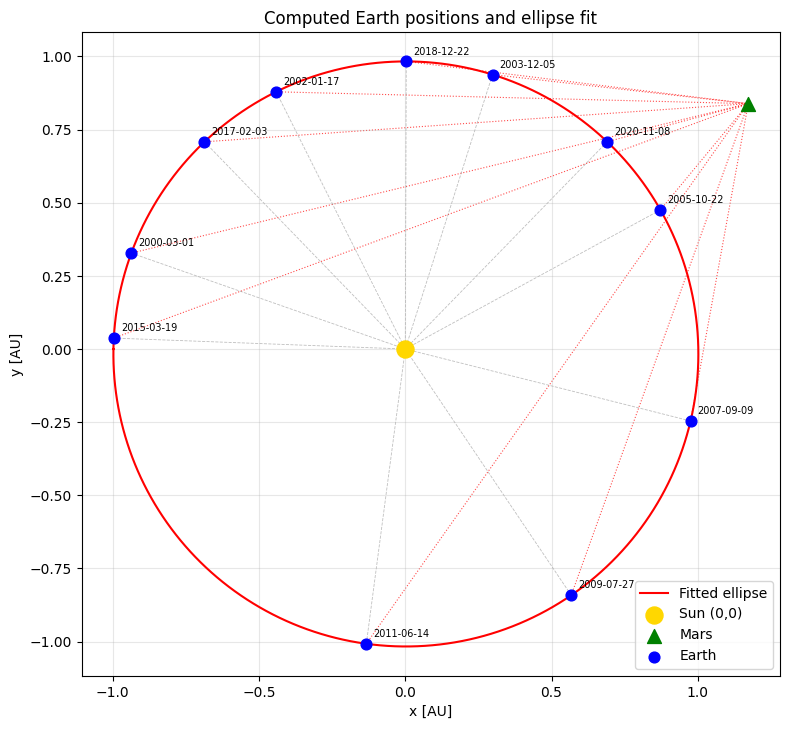

In [667]:
lons = selected_df['Sun Ecliptic Longitude (deg)'].values / 360 * 2 * np.pi
earth_x, earth_y = points_ellipse(lons, e, omega)

# Full ellipse curve for plotting
theta = np.linspace(0, 2 * np.pi, 500)
ellipse_x, ellipse_y = points_ellipse(theta, e, omega)

# --- Plot ---
fig, ax = plt.subplots(figsize=(8, 8))

# Fitted ellipse
ax.plot(ellipse_x, ellipse_y, 'r-', linewidth=1.5, label='Fitted ellipse', zorder=2)

# # Sightlines: Earth → Mars (red dotted)
for ex, ey in zip(earth_x, earth_y):
    ax.plot([ex, mars_x], [ey, mars_y], 'r:', linewidth=0.8, alpha=0.7, zorder=1)

# Sightlines: Earth → Sun (gray dashed)
for ex, ey in zip(earth_x, earth_y):
    ax.plot([ex, 0], [ey, 0], 'gray', linewidth=0.6, linestyle='--', alpha=0.5, zorder=1)

# Sun
ax.scatter(0, 0, color='gold', s=150, zorder=5, label='Sun (0,0)')

# Mars
ax.scatter(mars_x, mars_y, color='green', s=100, marker='^', zorder=5, label='Mars')

# Earth positions
ax.scatter(earth_x, earth_y, color='blue', s=60, zorder=4, label='Earth')

# Date labels
for ex, ey, date in zip(earth_x, earth_y, selected_df['Date']):
    ax.annotate(str(date)[:10], (ex, ey),
                textcoords='offset points', xytext=(5, 5),
                fontsize=7, color='black')

ax.set_aspect('equal')
ax.set_xlabel('x [AU]')
ax.set_ylabel('y [AU]')
ax.set_title('Computed Earth positions and ellipse fit')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Statistical analysis of the fit

The fitting process above, as indicated, does not use the uncertainty associated to the measurements. Below, we are going to fit an statistical model that will provide us with estimations of the variance associated to the unknown parameters and, in particular, to the eccentricity.

This estimation of the variability of the calculated eccentricity will be used to rule out the hypothesis of the circularity of the Earth's orbit.

In [ ]:
import numpyro
import numpyro.distributions as dist
from numpyro.handlers import condition
from numpyro.infer import MCMC, NUTS
from numpyro.infer.util import Predictive
from jax import random

import jax.numpy as jnp

import arviz as az

rng_key = random.PRNGKey(seed=42)

Here I translate degrees to radians.

In [669]:
sun_longitudes = selected_df['Sun Ecliptic Longitude (deg)'].values / 360 * 2 * np.pi
mars_longitudes = selected_df['Mars Ecliptic Longitude (deg)'].values / 360 * 2 * np.pi
mars_longitudes = np.arctan(np.tan(mars_longitudes))
sun_longitudes, mars_longitudes

(array([5.9465008 , 5.17778432, 4.40462439, 3.64085274, 2.89448462,
        2.16383704, 1.4393195 , 6.24564586, 5.48216686, 4.70903883,
        3.940073  ]),
 array([ 0.23734688, -0.02528629, -0.11471435,  0.87918254,  1.39174101,
         1.22515847,  0.95500873,  0.35463218,  0.07089539, -0.12245375,
         0.26513766]))

### Model creation and fit

In [ ]:
def points_ellipse_alt(rho, e, omega):
    """
    This is a rewrite of the previous function using JAX's numpy version.
    """
    theta = rho + jnp.pi
    r = (1 - e**2) / (1 + e * jnp.cos(theta - omega))
    x = r * jnp.cos(theta)
    y = r * jnp.sin(theta)
    return x, y


def model(sun_longitudes):

    # ---------------------------------------------------------------------------
    # pre-priors (to avoid sampling issues)
    # ---------------------------------------------------------------------------
    mars_x_error = numpyro.sample('mars_x_error', dist.Normal(0.0, 1.0))
    mars_y_error = numpyro.sample('mars_y_error', dist.Normal(0.0, 1.0))
    e_error      = numpyro.sample('e_error',      dist.HalfNormal(1.0))

    # ---------------------------------------------------------------------------
    # proper priors
    # ---------------------------------------------------------------------------

    mars_x = numpyro.deterministic('mars_x', mars_x_approx + mars_x_error * 0.01)
    mars_y = numpyro.deterministic('mars_y', mars_y_approx + mars_y_error * 0.01)
    omega  = numpyro.sample('omega',  dist.Normal(omega_approx, 0.5))
    e      = numpyro.deterministic('e', e_error * 0.01)
    observations_sigma = 0.001

    # ---------------------------------------------------------------------------
    # actual model
    # ---------------------------------------------------------------------------

    # place the Earth on a "random ellipse"
    ex, ey = points_ellipse_alt(sun_longitudes, e, omega)

    # estimate Mars logitudes from the Earth positions
    tans = (mars_y - ey) / (mars_x - ex)
    mars_longitudes_mu = jnp.arctan(tans)

    # match estimated longitudes to observed ones
    numpyro.sample("mars_longitudes", dist.Normal(loc=mars_longitudes_mu, scale = observations_sigma))

    return(mars_longitudes_mu)


It is possible to generate a prior distribution of the involved parameters (without using observed data) running the following code:

In [689]:
prior_predictive = Predictive(model, num_samples=500)
rng_key, rng_subkey = random.split(rng_key)
prior_samples = prior_predictive(rng_subkey, sun_longitudes)

Fitting the model. 

First, we _condition_ the model so that the `mars_longitudes` are set to the observed ones. Then we run an MCMC process to estimate the parameters.

In [690]:
conditioned_model = condition(model, {"mars_longitudes": mars_longitudes})

nuts_kernel = NUTS(conditioned_model)
mcmc = MCMC(nuts_kernel, num_warmup=1_000, num_samples=1_000, num_chains=4)
rng_key, rng_subkey = random.split(rng_key)
mcmc.run(rng_subkey, sun_longitudes)

/tmp/ipykernel_305374/2854382959.py:4: UserWarning: There are not enough devices to run parallel chains: expected 4 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(4)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(nuts_kernel, num_warmup=1_000, num_samples=1_000, num_chains=4)
sample: 100%|██████████| 2000/2000 [00:01<00:00, 1532.20it/s, 7 steps of size 3.38e-01. acc. prob=0.92] 


### Results

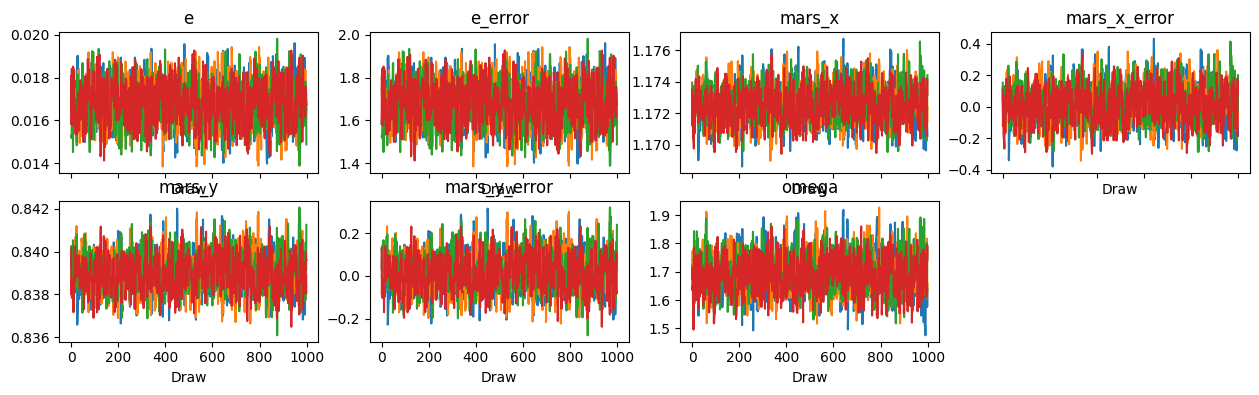

In [694]:
idata = az.from_numpyro(mcmc)
az.plot_trace(idata);

This are the posteriors estimations of the eccentricity of the Earth's orbit. It is to be noted how the mode of the distribution matches the known value of 0.0167.

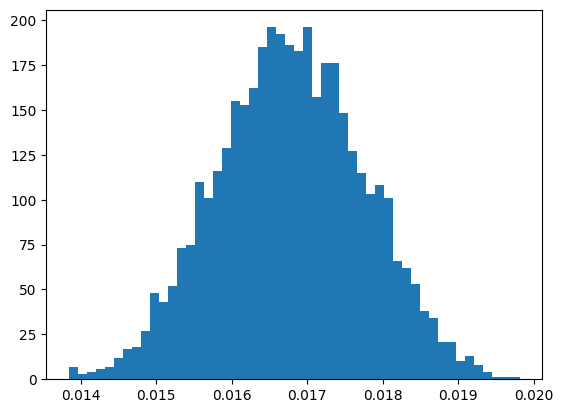

In [699]:
plt.hist(mcmc.get_samples()['e'], bins = 50);

And this is the estimation of the inclination of the Earth's orbit with respect to the original parametrization used to locate the origin of the Earth longitudes with respect to the Sun.

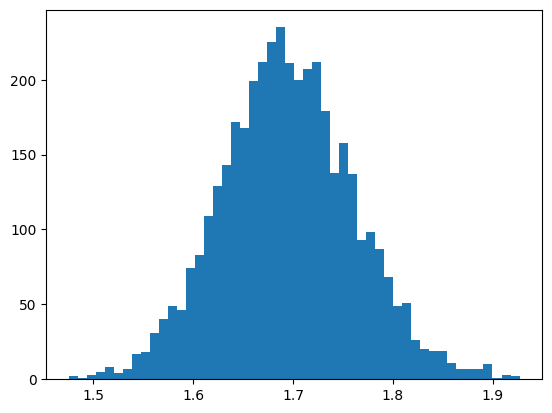

In [698]:
plt.hist(mcmc.get_samples()['omega'], bins = 50);

Finally, a plot of all the estimated orbits.   

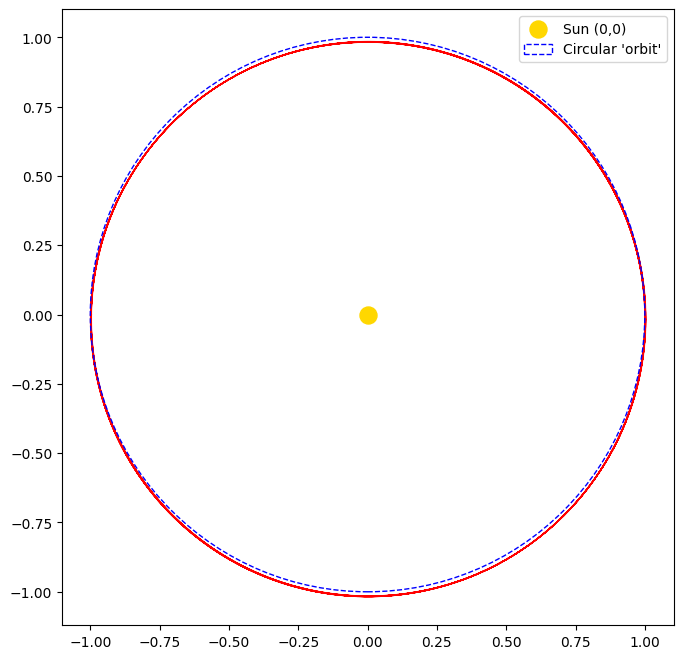

In [703]:
e_samples = mcmc.get_samples()['e']
omega_samples = mcmc.get_samples()['omega']

fig, ax = plt.subplots(figsize=(8, 8))

# Plot all sampled ellipses
for e_s, omega_s in zip(e_samples, omega_samples):
    ellipse_x, ellipse_y = points_ellipse(theta, e_s, omega_s)
    ax.plot(ellipse_x, ellipse_y, 'r-', linewidth=0.5, alpha=0.01, zorder=1)

# Sun
ax.scatter(0, 0, color='gold', s=150, zorder=5, label='Sun (0,0)')

# # MAP ellipse on top for reference
# ellipse_x_map, ellipse_y_map = points_ellipse(theta, e, omega)
# ax.plot(ellipse_x_map, ellipse_y_map, 'k-', linewidth=1.5, label='MAP ellipse', zorder=3)

circle = plt.Circle((0, 0), 1, color='blue', fill=False, linewidth=1, linestyle='--', label="Circular 'orbit'", zorder=2)
ax.add_patch(circle)

ax.set_aspect('equal')
ax.legend()
plt.show()